In [1]:
import numpy as nb
import cv2
import mediapipe as mp
from os import listdir
from os.path import isfile, join
import pandas as pd

from collections import defaultdict
import random

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from src.constants import ACTIONS
from src.frame import Frame

In [2]:
pose = mp.solutions.pose.Pose(min_detection_confidence=0.5, min_tracking_confidence=0.5)


I0000 00:00:1717150106.603400       1 gl_context.cc:344] GL version: 2.1 (2.1 Metal - 88.1), renderer: Apple M1


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [3]:
processed_files = []
sample_counts = defaultdict(int)

# Step 1: Count samples for each action
for index, action in enumerate(ACTIONS):
    path = f'./data/exercises/{action}'
    onlyfiles = [f for f in listdir(path) if isfile(join(path, f))]
    sample_counts[action] = len(onlyfiles)

# Step 2: Determine the target number of samples per action
target_samples = max(sample_counts.values())

# Step 3: Process and balance the samples
for index, action in enumerate(ACTIONS):
    path = f'./data/exercises/{action}'
    onlyfiles = [f for f in listdir(path) if isfile(join(path, f))]
    
    samples_per_action = []
    for j, i in enumerate(onlyfiles):
        img = cv2.imread(f'{path}/{i}')
        frame = Frame(img)
        result = pose.process(frame.frame)
        print(f'Processing file {j} for {action}') if j % 150 == 0 else None
        if result.pose_landmarks:
            frame.set_calculation_unit(result.pose_landmarks)
            sample_info = frame.calculation_unit.angle_dicts
            sample_info['label'] = index
            samples_per_action.append(sample_info)
    
    # Oversampling if needed
    while len(samples_per_action) < target_samples:
        samples_per_action.append(random.choice(samples_per_action))
    
    # Undersampling if needed
    if len(samples_per_action) > target_samples:
        samples_per_action = random.sample(samples_per_action, target_samples)
    
    processed_files.extend(samples_per_action)

Processing file 0 for plank
Processing file 150 for plank
Processing file 300 for plank
Processing file 450 for plank
Processing file 600 for plank
Processing file 750 for plank
Processing file 900 for plank
Processing file 0 for romanian_deadlift
Processing file 150 for romanian_deadlift
Processing file 300 for romanian_deadlift
Processing file 450 for romanian_deadlift
Processing file 0 for russian_twist
Processing file 150 for russian_twist
Processing file 300 for russian_twist
Processing file 450 for russian_twist
Processing file 0 for squat
Processing file 150 for squat
Processing file 300 for squat
Processing file 450 for squat
Processing file 600 for squat


In [4]:
csv_data = pd.DataFrame(processed_files)
csv_data.to_csv('./data/angled_data.csv', index=False)

In [5]:
#counts the frequency of each class
print(csv_data['label'].value_counts())


label
0    993
1    993
2    993
3    993
Name: count, dtype: int64


In [4]:
# Shuffle the DataFrame
df = pd.read_csv('./data/angled_data.csv')
df = df.sample(frac=1).reset_index(drop=True)

In [22]:
df[df['label'] == 5].head()

,right_knee,left_knee,right_hip,left_hip,right_shoulder,left_shoulder,right_elbow,left_elbow,label
2,169.238206,177.671552,164.561810,177.053121,179.926015,165.142456,76.821728,111.725114,5
3,62.627412,106.539886,90.009577,110.081440,22.710753,151.001158,28.633834,36.150020,5
8,34.995963,167.917890,157.184597,151.335476,133.045401,112.491120,155.291014,152.523240,5
42,174.742875,178.469169,178.667531,173.131412,115.792893,86.489348,162.252904,176.942402,5
45,155.652732,161.280042,160.295361,175.040569,110.975737,91.107006,146.831028,36.899530,5


In [23]:
#normalzing the data
df = df.drop('label', axis=1)
df = (df - df.min()) / (df.max() - df.min())

X = df
y = pd.read_csv('./data/angled_data.csv')['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
# Create and train the Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict the labels and probabilities
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)
train_probs = model.predict_proba(X_train)
test_probs = model.predict_proba(X_test)

# Calculate train and test accuracy
train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)
print(f"Train accuracy: {train_acc:.5f}")
print(f"Test accuracy: {test_acc:.5f}")

# Show an example of inference
example = X_test.iloc[0]
example_prediction = model.predict([example])
print(f"Example truth: {y_test.iloc[0]} Prediction: {example_prediction}")

Train accuracy: 1.00000
Test accuracy: 0.17894
Example truth: 3 Prediction: [2]


/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


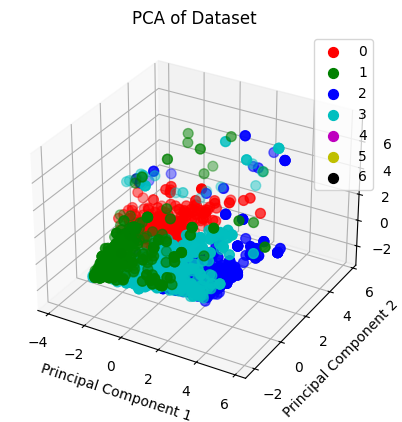

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Importing 3D plotting tools
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Sample DataFrame 'df' with numerical features and a categorical 'label'
df = pd.read_csv('./data/angled_data.csv')
# Standardize the features
features = df.columns.difference(['label'])
x = df.loc[:, features].values
y = df.loc[:, 'label'].values
x = StandardScaler().fit_transform(x)

# PCA to reduce dimensions to 3D
pca = PCA(n_components=3)
principal_components = pca.fit_transform(x)
principal_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2', 'PC3'])

# Concatenate with the target label
final_df = pd.concat([principal_df, pd.DataFrame(y, columns=['label'])], axis=1)

# Plotting in 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

colors = {0: 'r', 1: 'g', 2: 'b', 3: 'c'}  # Adjust colors if needed

for label, color in colors.items():
    indicesToKeep = final_df['label'] == label
    ax.scatter(final_df.loc[indicesToKeep, 'PC1'],
               final_df.loc[indicesToKeep, 'PC2'],
               final_df.loc[indicesToKeep, 'PC3'], c=color, s=50)

ax.legend(colors.keys())
ax.set_title('PCA of Dataset')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
plt.show()


In [33]:
pd = pd.read_csv('./data/angled_data.csv')
X, y = pd.drop('label', axis=1), pd['label']
X_normalized = (X - X.min()) / (X.max() - X.min())

X_train, X_test, y_train, y_test = train_test_split(X_normalized, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

train_preds = model.predict(X_train)

test_preds = model.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)

test_acc = accuracy_score(y_test, test_preds)

print(f"Train accuracy: {train_acc:.5f}")

print(f"Test accuracy: {test_acc:.5f}")

Train accuracy: 1.00000
Test accuracy: 0.67271


In [34]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(random_state=42)

model.fit(X_train, y_train)

train_preds = model.predict(X_train)

test_preds = model.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)

test_acc = accuracy_score(y_test, test_preds)

print(f"Train accuracy: {train_acc:.5f}")

print(f"Test accuracy: {test_acc:.5f}")

Train accuracy: 0.84046
Test accuracy: 0.66818


In [36]:
#support vector machine with non linearities
from sklearn.svm import SVC

model = SVC(kernel='rbf', random_state=42)

model.fit(X_train, y_train)

train_preds = model.predict(X_train)

test_preds = model.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)

test_acc = accuracy_score(y_test, test_preds)

print(f"Train accuracy: {train_acc:.5f}")

print(f"Test accuracy: {test_acc:.5f}")


Train accuracy: 0.71097
Test accuracy: 0.65912


In [41]:
#one layer MLP

from sklearn.neural_network import MLPClassifier

model = MLPClassifier(hidden_layer_sizes=(200,), max_iter=3000, random_state=42)

model.fit(X_train, y_train)

train_preds = model.predict(X_train)

test_preds = model.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)

test_acc = accuracy_score(y_test, test_preds)

print(f"Train accuracy: {train_acc:.5f}")

print(f"Test accuracy: {test_acc:.5f}")

Train accuracy: 0.72343
Test accuracy: 0.66365


In [ ]:
from src.exercise import Exercise

exercise = Exercise()

exercise.train_model()

#save the model

import joblib

joblib.dump(exercise.model, './models/exercise_model.pkl')






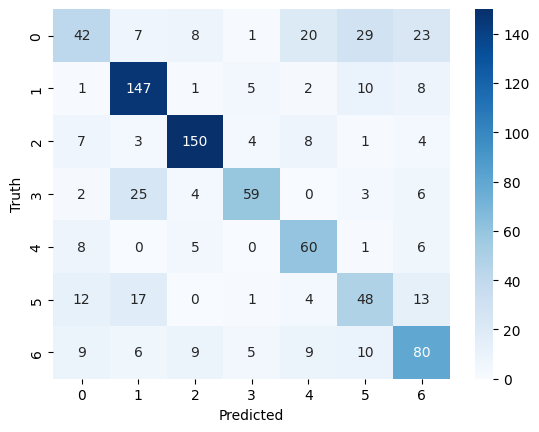

In [44]:
#plot confusion matrix
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, test_preds)

import seaborn as sns

sns.heatmap(confusion_matrix(y_test, test_preds), annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')

plt.ylabel('Truth')

plt.show()